# Librerías

In [1]:
import pandas as  pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Input

Creación del dataframe

In [2]:
# Path de la data csv
path = "/content/drive/MyDrive/Glac_SARglac/SAR_glac_codigo/SAR_glac_input/SarGlac_input_AE_2022_1000_Points.csv"
# Creación del Dataframe
df = pd.read_csv(path, sep= (','))

# Renombrar columna de orbit propertires
df.rename(columns={"orbitProperties_pass": "orbita"}, inplace=True)
df.orbita = df.orbita.replace({'ASCENDING': "ASC", 'DESCENDING': "DESC"})
#Columna con datetime
df['datetime'] =  pd.to_datetime(df['datetime'])

# Procesamiento

In [3]:
#Datos útiles
print('Elevación mínima:', df.elevation.min())
print('Elevación máxima:', df.elevation.max())

Elevación mínima: 5631.0
Elevación máxima: 6222.0


In [4]:
#Agregar data del mes y de año
df['Mes'] = pd.DatetimeIndex(df['datetime']).month
df['Año'] = pd.DatetimeIndex(df['datetime']).year
df['Dia'] = pd.DatetimeIndex(df['datetime']).day
df['Hora'] = pd.DatetimeIndex(df['datetime']).hour - 5 #Por las 5 horas de UTC-5 #UTC:23/10 // 18/5
df['Minuto'] = pd.DatetimeIndex(df['datetime']).minute

[Ref clasificación aspect](https://www.researchgate.net/publication/306526329_GIS_based_landslide_susceptibility_mapping_of_northern_areas_of_Pakistan_a_case_study_of_Shigar_and_Shyok_Basins)

In [5]:
#Clasifica el aspecto
def clasif_aspect(i):
  if 337.5 <= i < 370:
    return 'N'
  if 0    <= i < 22.5:
    return 'N'      
  if 22.5 <= i < 67.5:
    return 'NE'
  if 67.5 <= i < 112.5:
    return 'E'
  if 112.5 <= i < 157.5:
    return 'SE'
  if 157.5 <= i < 202.5:
    return 'S'
  if 202.5 <= i < 247.5:
    return 'SW'
  if 247.5 <= i < 292.5:
    return 'W'
  if 292.5 <= i < 337.5:
    return 'NW'

df['aspect_c'] = df['aspect'].map(clasif_aspect)

0          N
1         SE
2         NE
3         NW
4          E
          ..
273727     N
273728    NE
273729    NW
273730    NW
273731     W
Name: aspect_c, Length: 273732, dtype: object

In [8]:
#Estratificar por altitud
lista_rangos_20 = range(5620, 6240, 20)
lista_rangos_100 = range(5600, 6300, 100)
df['agrup20'] = pd.cut(df.elevation, lista_rangos_20)
df['agrup100'] = pd.cut(df.elevation, lista_rangos_100)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 273732 entries, 0 to 273731
Data columns (total 16 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   datetime   273732 non-null  datetime64[ns]
 1   VV         273732 non-null  float64       
 2   VH         273732 non-null  float64       
 3   angle      273732 non-null  float64       
 4   elevation  273732 non-null  float64       
 5   aspect     273732 non-null  float64       
 6   slope      273732 non-null  float64       
 7   orbita     273732 non-null  object        
 8   Mes        273732 non-null  int64         
 9   Año        273732 non-null  int64         
 10  Dia        273732 non-null  int64         
 11  Hora       273732 non-null  int64         
 12  Minuto     273732 non-null  int64         
 13  aspect_c   273732 non-null  object        
 14  agrup20    273532 non-null  category      
 15  agrup100   268990 non-null  category      
dtypes: category(2), date

In [9]:
#Dataframes con órbita Ascendente y Descendente
df_asc = df.loc[df.orbita == 'ASC'] #Hora: 18
df_desc = df.loc[df.orbita == 'DESC'] #Hora 5

In [10]:
df.sample(n=3)

,datetime,VV,VH,angle,elevation,aspect,slope,orbita,Mes,Año,Dia,Hora,Minuto,aspect_c,agrup20,agrup100
186026,2020-05-27 23:16:12,-5.409415,-12.501037,34.961750,6044.0,103.541534,7.872272,ASC,5,2020,27,18,16,E,"(6040, 6060]","(6000, 6100]"
122576,2019-04-15 23:16:03,0.699563,-6.678769,34.603886,6068.0,258.335388,13.506335,ASC,4,2019,15,18,16,W,"(6060, 6080]","(6000, 6100]"
184540,2020-05-15 23:16:11,4.871407,-5.230610,35.156395,6091.0,255.591873,14.586291,ASC,5,2020,15,18,16,W,"(6080, 6100]","(6000, 6100]"


# Análisis de datos

## Distribución de datos

In [11]:
plt.rc(
    "figure",
    autolayout=True, #~Ajusta los subplots params to fit
    # titlesize=18,
    titleweight='bold',
)
plt.rc(
    "axes",
    labelweight="bold",
    titleweight="bold",
    titlesize=16,
    titlepad=10,
)

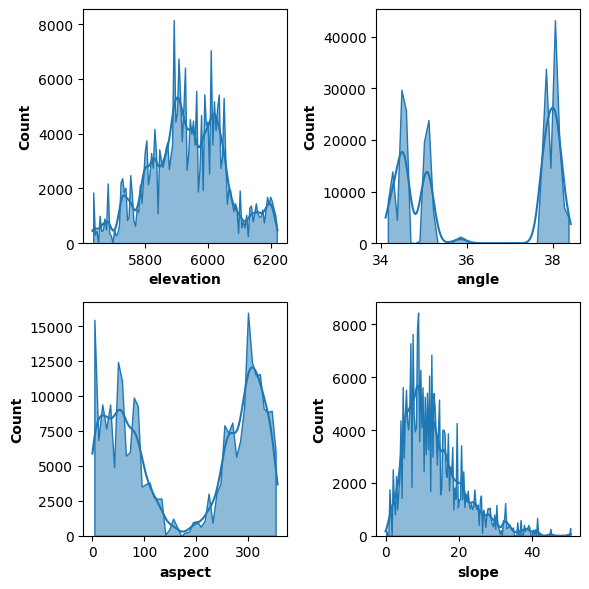

In [12]:
# @title Histograma de elevación, ángulo, aspecto y pendiente
#set figure
fig, ax = plt.subplots(2, 2, figsize=(6, 6), dpi=100 ) 
#Figuras individuales
plt.subplot(2,2,1)
sns.histplot(df.elevation,element='poly', kde=True)
plt.subplot(2,2,2)
sns.histplot(df.angle,  element='poly', kde=True)
plt.subplot(2,2,3)
sns.histplot(df.aspect, element='poly', kde=True)
plt.subplot(2,2,4)
sns.histplot(df.slope,  element='poly', kde=True)

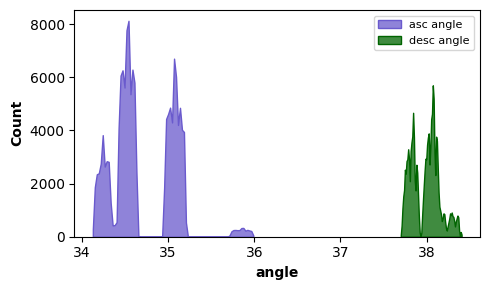

In [13]:
#Distinción de la distribución de los ángulos
plt.figure(figsize=(5,3), dpi= 100)
sns.histplot(df_asc.angle,  color="slateblue", label="asc angle", element='poly')
sns.histplot(df_desc.angle, color="darkgreen", label="desc angle", element='poly')
plt.legend(fontsize= 8);

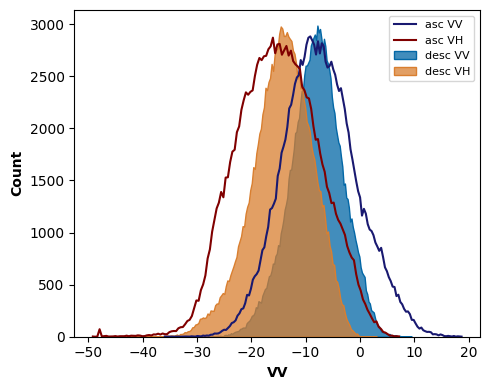

In [14]:
#Distribución de la retrodispersión
plt.figure(figsize=(5,4), dpi= 100)

# VV
sns.histplot(df_desc.VV, color="#0367A6",   label="desc VV", element='poly', fill=1)
sns.histplot(df_asc.VV, color="midnightblue", label="asc VV", element='poly', fill=0)
#VH
sns.histplot(df_desc.VH, color="#D97F30",   label="desc VH",  element='poly', fill=1)
sns.histplot(df_asc.VH, color="maroon",     label="asc VH",   element='poly', fill=0)

plt.legend(fontsize= 8);

Text(0, 0.5, '')

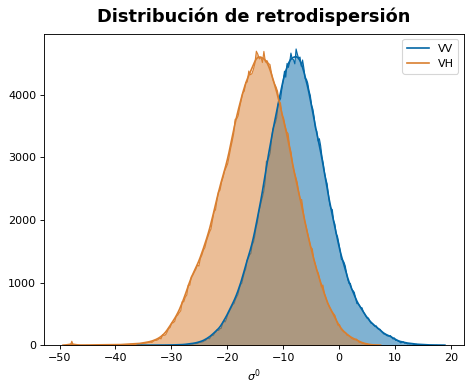

In [15]:
# Artist
fig, ax = plt.subplots(figsize=(6, 5), dpi=80)

# 
sns.histplot(df.VV, color = '#0367A6', legend=True, kde=1, element="poly")
sns.histplot(df.VH, color = '#D97F30', legend=True, kde=1, element="poly")
#Fig elements
plt.title('Distribución de retrodispersión')
plt.legend(labels=["VV","VH"])
plt.xlabel(r"$\sigma^0$" )
plt.ylabel('')

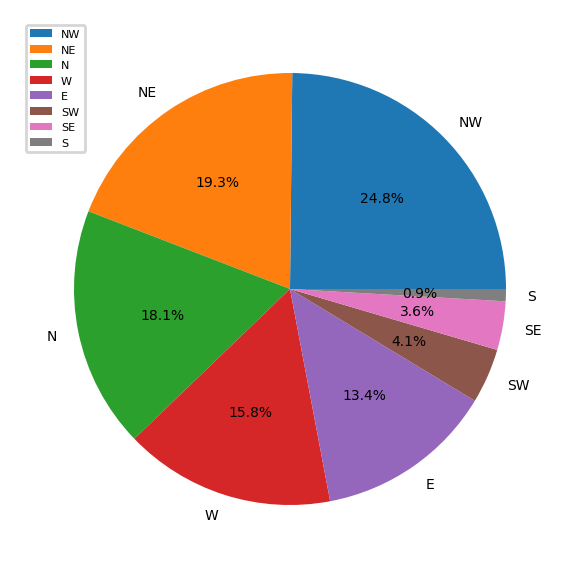

In [17]:
#Piechart con orientación 
#Figure
plt.figure(figsize=(3, 3), dpi= 200)
#Nombres de los aspectos
list_asp = df.aspect_c.value_counts(normalize=1).index.tolist()
#Pie chart
plt.pie(df.aspect_c.value_counts(normalize=True), autopct='%1.1f%%',
        textprops={'fontsize': 5}, shadow=0, labels =list_asp)
plt.legend(fontsize = 4)

## Elevación y backs

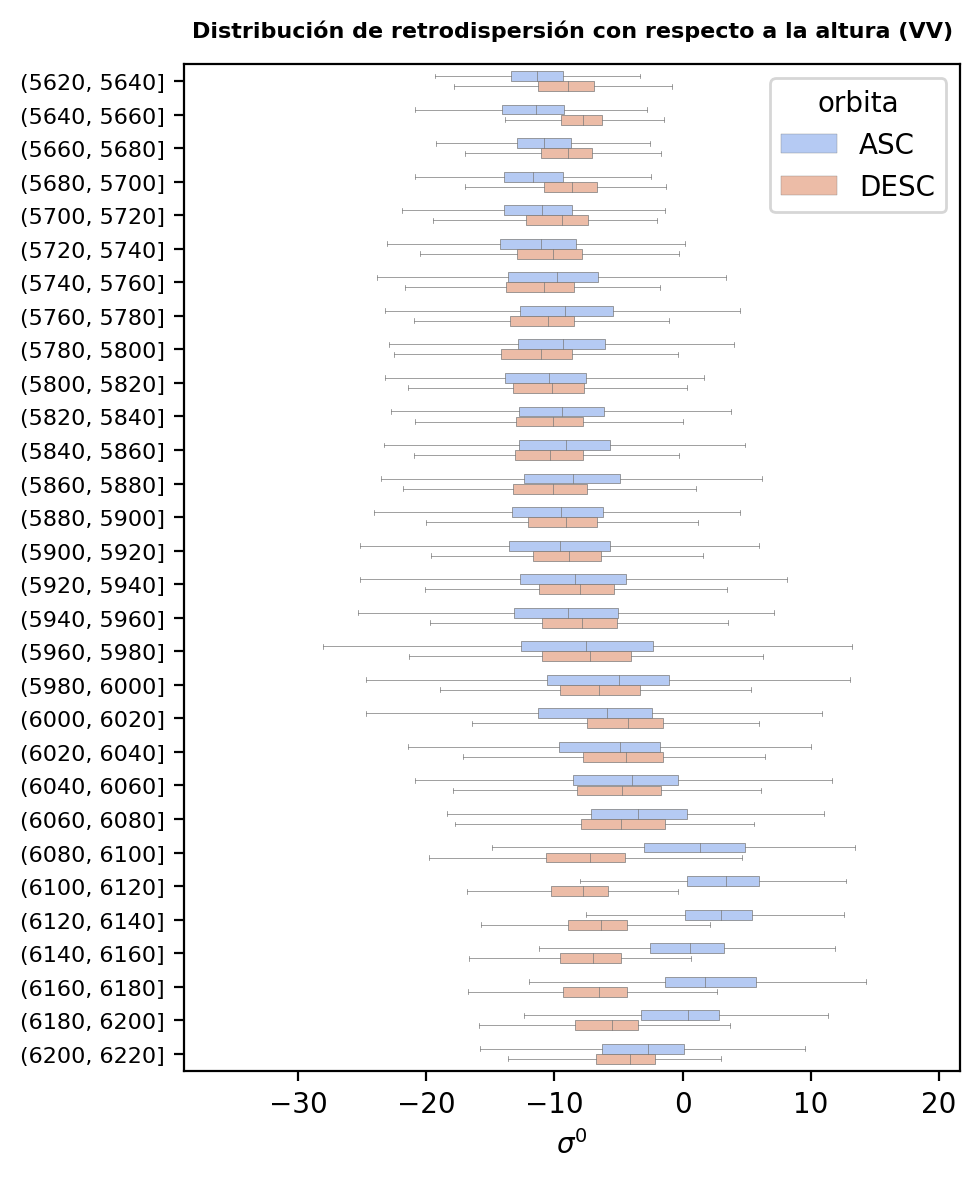

In [46]:
# Boxplot
#Artist
fig, ax = plt.subplots(figsize=(5, 6), dpi=200)
sns.boxplot(data = df, x = 'VV', y = 'agrup20', hue= 'orbita', 
            width= 0.6, linewidth=0.25, fliersize=0,
            palette='coolwarm' )

#Fig elements
plt.title(fontsize=8, label= 'Distribución de retrodispersión con respecto a la altura (VV)')
plt.xlabel(r"$\sigma^0$" )
plt.ylabel('', fontsize=2)
plt.tick_params(axis = 'y', labelsize=8)

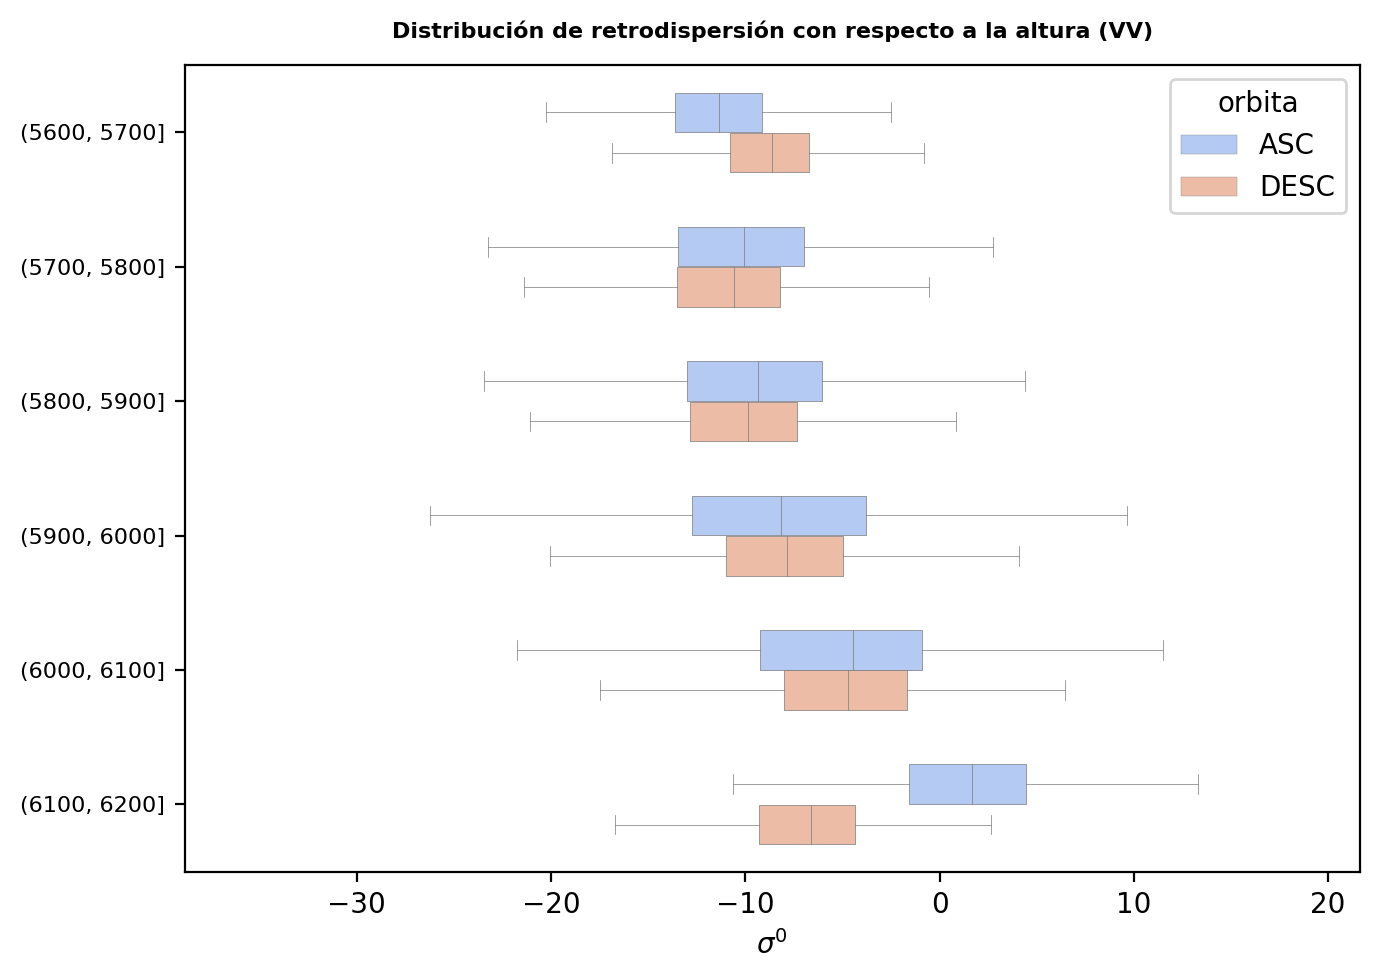

In [47]:
# Boxplot
#Artist
fig, ax = plt.subplots(figsize=(7, 5), dpi=200)
sns.boxplot(data = df, x = 'VV', y = 'agrup100', hue= 'orbita',
            width= 0.6, linewidth=0.25, fliersize=0,
            palette='coolwarm' )

#Fig elements
plt.title(fontsize=8, label= 'Distribución de retrodispersión con respecto a la altura (VV)')
plt.xlabel(r"$\sigma^0$" )
plt.ylabel('', fontsize=2)
plt.tick_params(axis = 'y', labelsize=8)

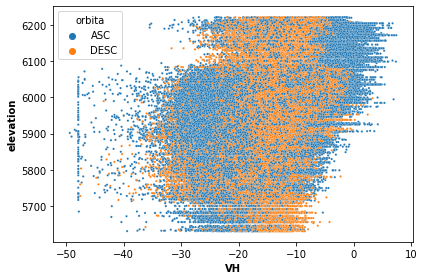

In [32]:
sns.scatterplot(x= 'VH', y= 'elevation', hue= 'orbita', data= df, color=".15", s=5)

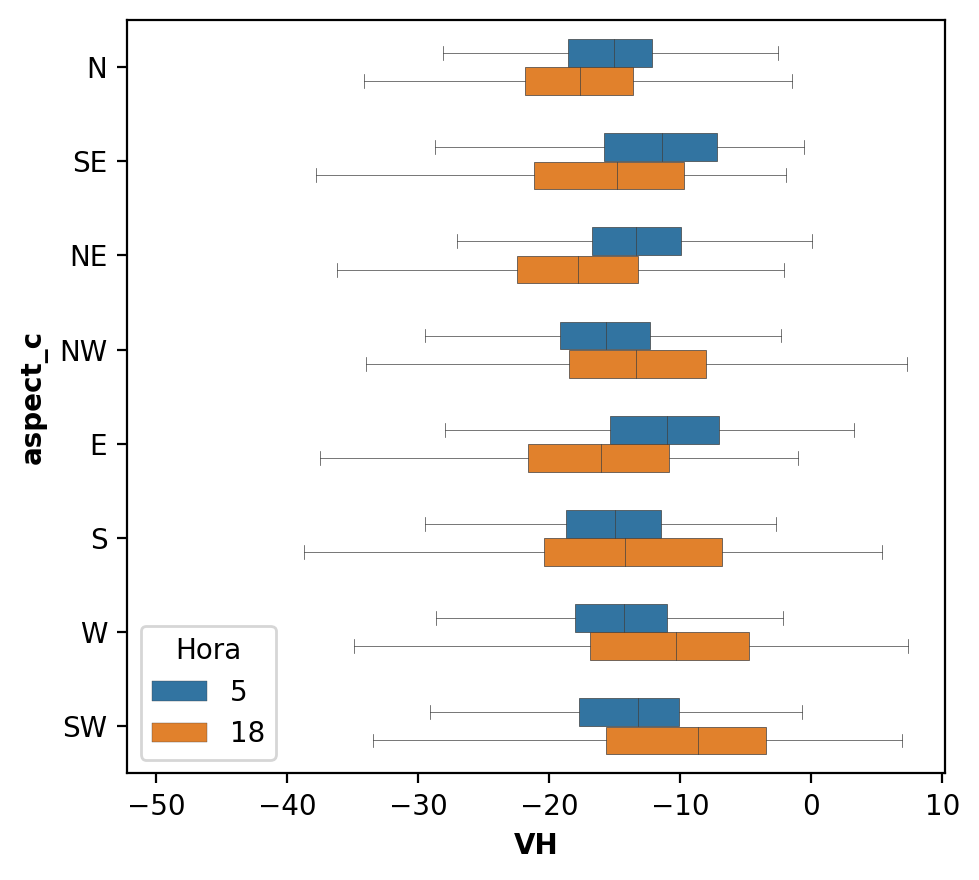

In [62]:
fig, ax = plt.subplots(figsize=(5, 4.5), dpi=200)
sns.boxplot(data= df,  x= 'VH', y= 'aspect_c', hue= 'Hora',
            width= 0.6, linewidth=0.25, fliersize=0)

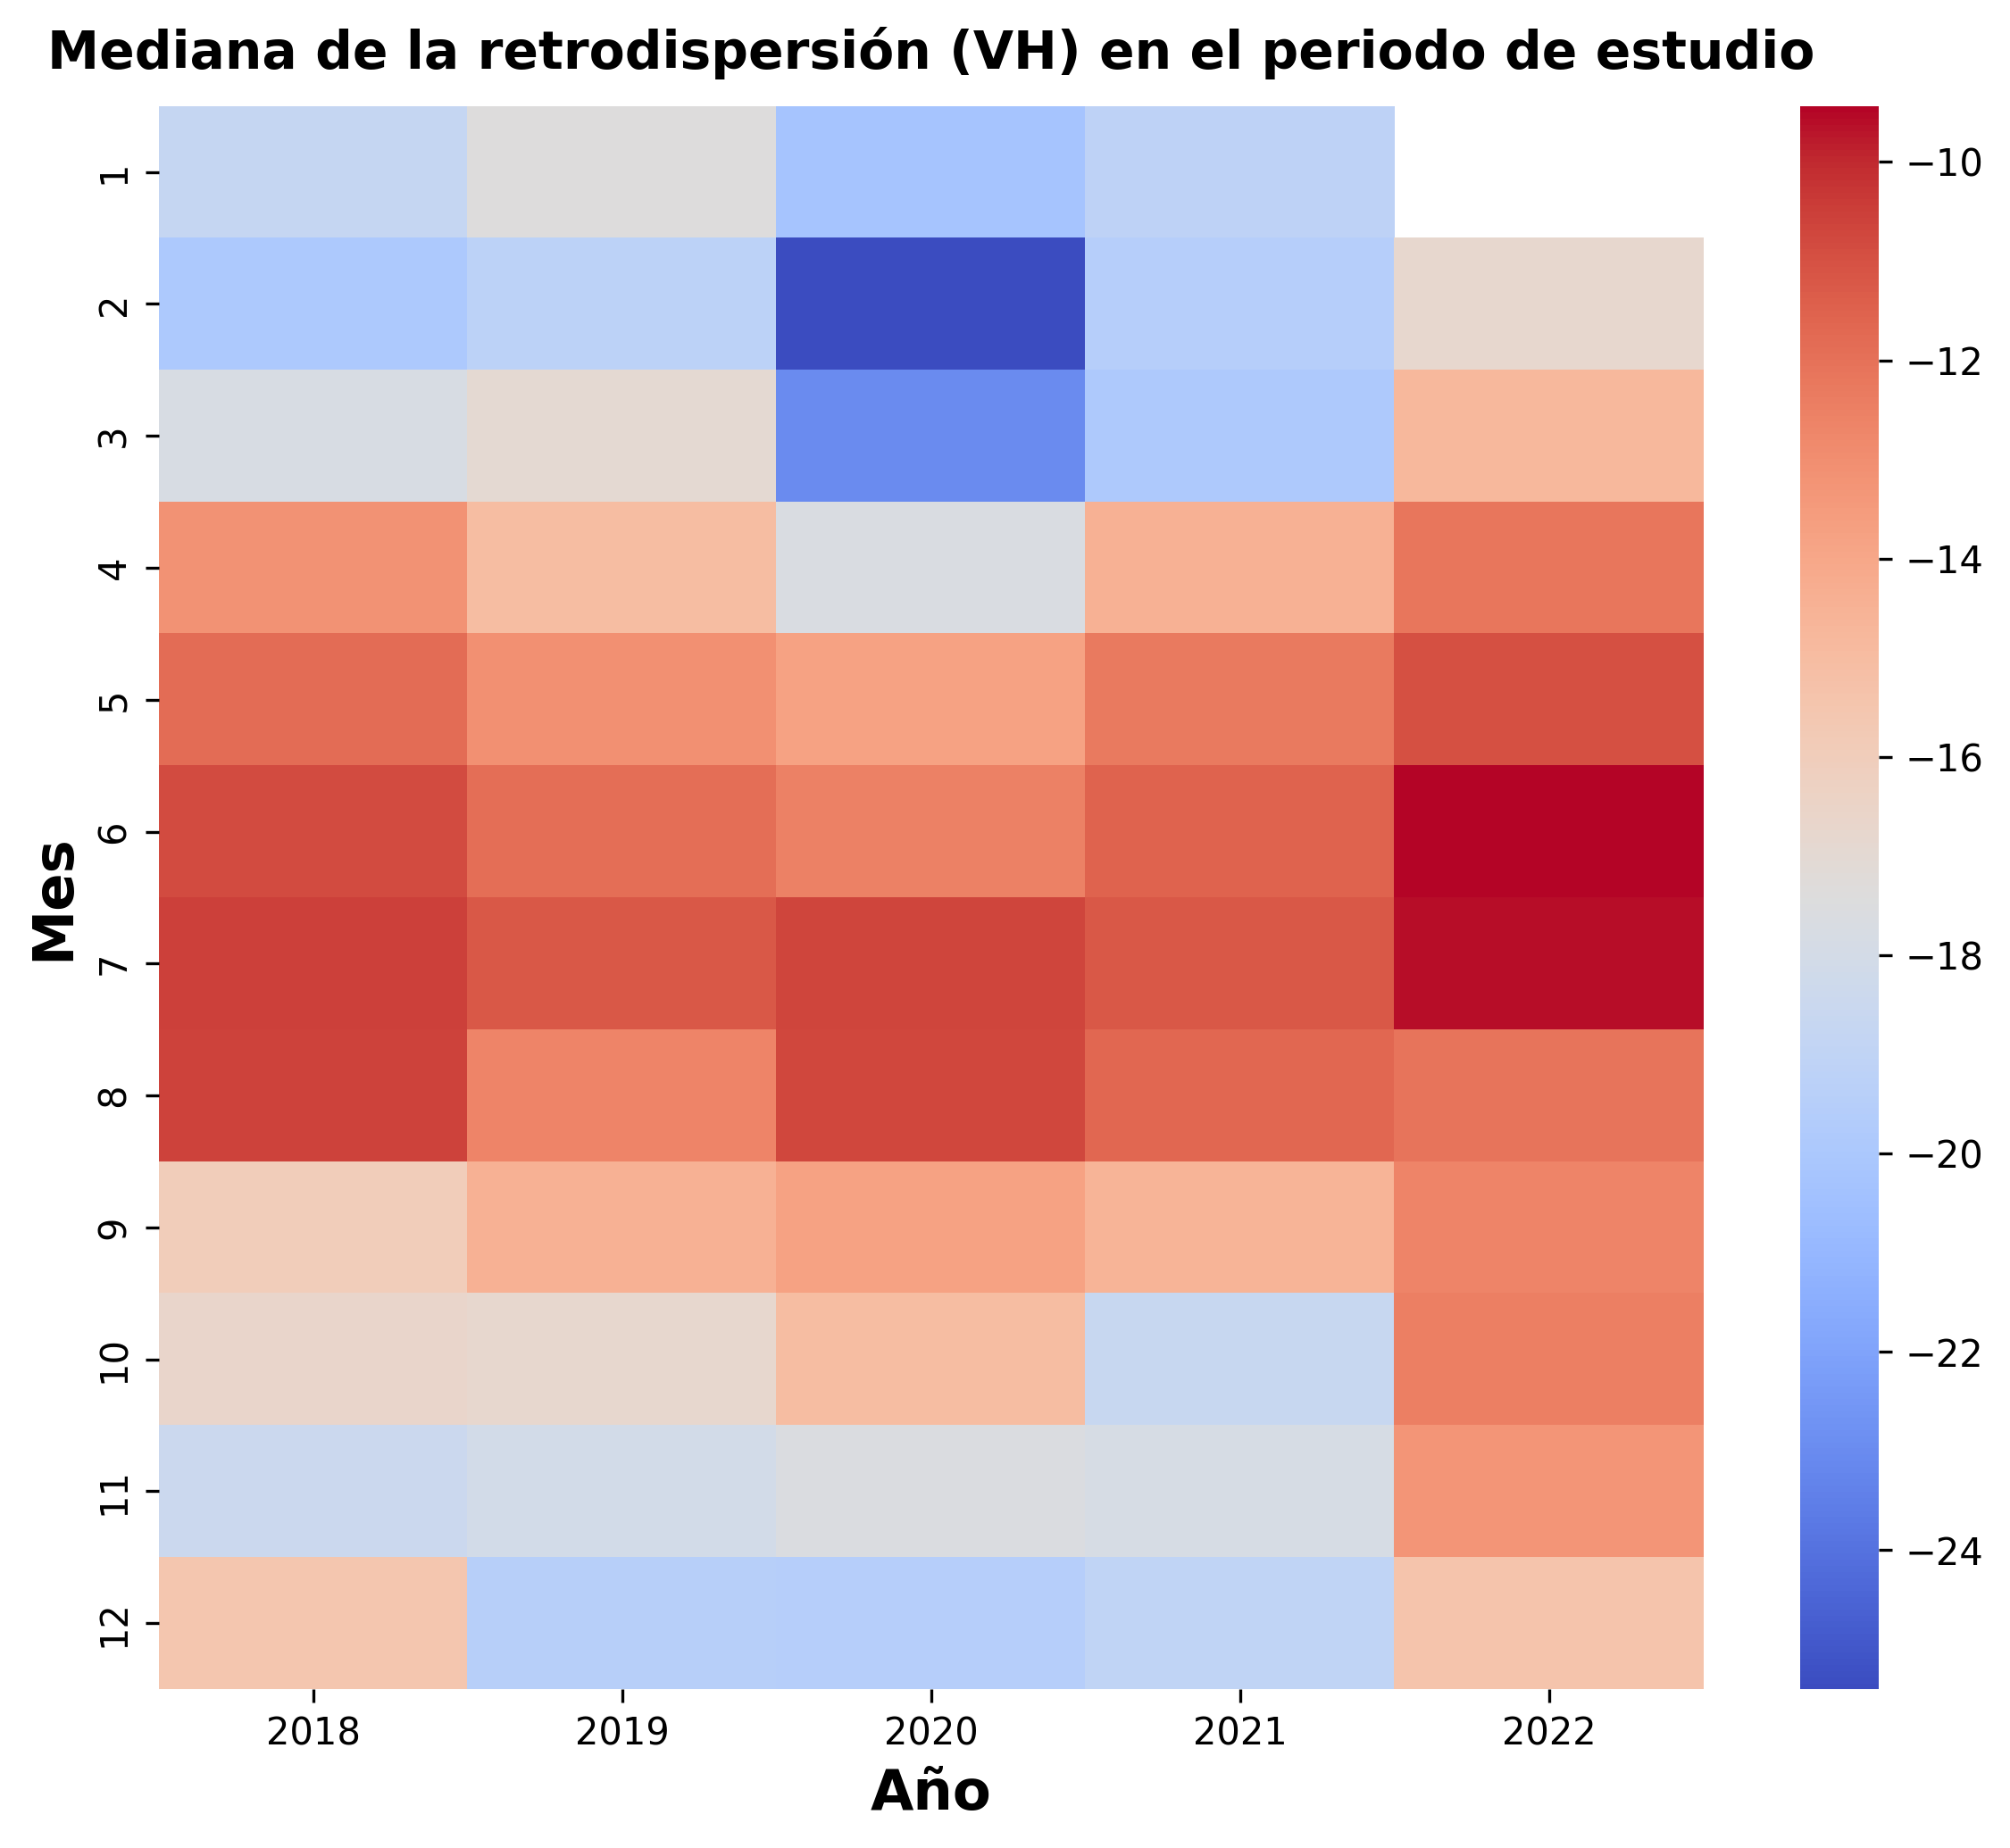

In [64]:
#Proceso
pivotear = df.pivot_table(index="Mes",columns="Año",values="VH", aggfunc="median")

#
plt.figure(figsize=(8,7), dpi =300)

# diverging_colors = sns.color_palette("RdBu", 10)
ax = sns.heatmap(pivotear, fmt=".1f", cmap='coolwarm', annot=False)

#Fig elements
plt.title(fontsize=14, label= 'Mediana de la retrodispersión (VH) en el periodo de estudio')

ax.set_xlabel('Año').set_size(15)
ax.set_ylabel('Mes').set_size(15)

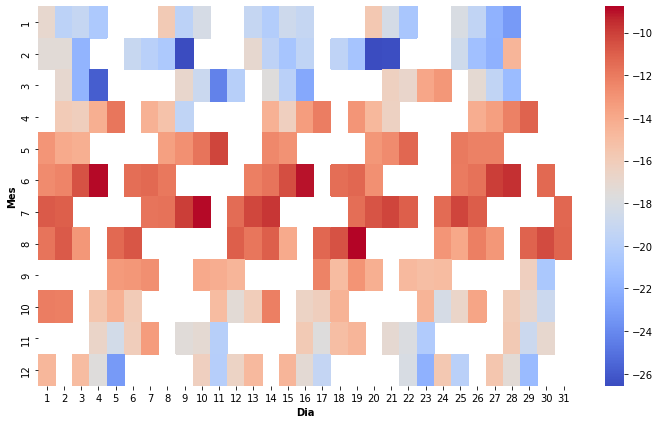

In [66]:
pivotea2r = df.pivot_table(index="Mes",columns="Dia",values="VH", aggfunc="median")
plt.figure(figsize=(10,6))
ax = sns.heatmap(pivotea2r, fmt=".1f", cmap='coolwarm')
# ax.set_xlabel('Month').set_size(20)
# ax.set_ylabel('Year').set_size(20)

[Text(0, 0.5, '5631.0'),
 Text(0, 9.5, '5636.0'),
 Text(0, 18.5, '5645.0'),
 Text(0, 27.5, '5659.0'),
 Text(0, 36.5, '5666.0'),
 Text(0, 45.5, '5674.0'),
 Text(0, 54.5, '5700.0'),
 Text(0, 63.5, '5711.0'),
 Text(0, 72.5, '5718.0'),
 Text(0, 81.5, '5723.0'),
 Text(0, 90.5, '5729.0'),
 Text(0, 99.5, '5735.0'),
 Text(0, 108.5, '5741.0'),
 Text(0, 117.5, '5746.0'),
 Text(0, 126.5, '5754.0'),
 Text(0, 135.5, '5760.0'),
 Text(0, 144.5, '5767.0'),
 Text(0, 153.5, '5773.0'),
 Text(0, 162.5, '5779.0'),
 Text(0, 171.5, '5785.0'),
 Text(0, 180.5, '5791.0'),
 Text(0, 189.5, '5796.0'),
 Text(0, 198.5, '5801.0'),
 Text(0, 207.5, '5806.0'),
 Text(0, 216.5, '5811.0'),
 Text(0, 225.5, '5816.0'),
 Text(0, 234.5, '5821.0'),
 Text(0, 243.5, '5826.0'),
 Text(0, 252.5, '5831.0'),
 Text(0, 261.5, '5836.0'),
 Text(0, 270.5, '5842.0'),
 Text(0, 279.5, '5847.0'),
 Text(0, 288.5, '5852.0'),
 Text(0, 297.5, '5857.0'),
 Text(0, 306.5, '5862.0'),
 Text(0, 315.5, '5867.0'),
 Text(0, 324.5, '5872.0'),
 Text(0, 333.5,

<Figure size 4200x6600 with 0 Axes>

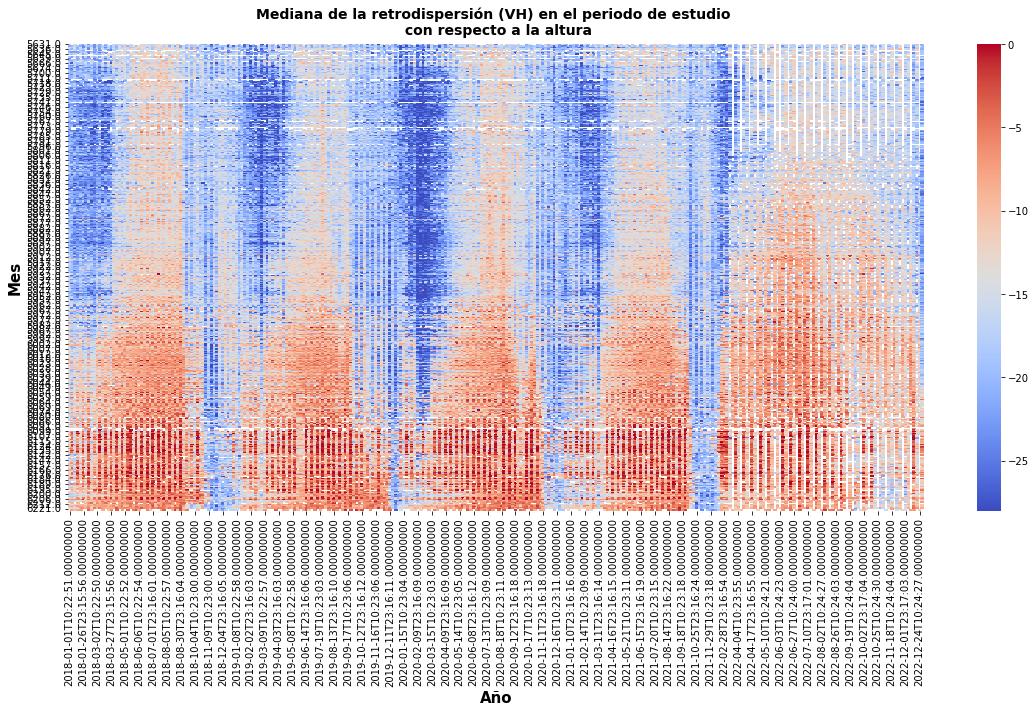

In [68]:
plt.figure(figsize=(14,22), dpi =300)

pivotea2r = df.pivot_table(index="elevation",columns="datetime",
                             values="VH", aggfunc="median")
plt.figure(figsize=(16,10))
ax = sns.heatmap(pivotea2r, fmt=".1f", cmap='coolwarm'
                 ,vmin=-28, vmax=0)

#Fig elements
plt.title(fontsize=14, label= 'Mediana de la retrodispersión (VH) en el periodo de estudio \n con respecto a la altura')

ax.set_xlabel('Año').set_size(15)
ax.set_ylabel('Mes').set_size(15)
ax = plt.gca()
ax.set_yticks(range(0, pivotea2r.shape[0], 5))
yticklabels = pivotea2r.index[range(0, pivotea2r.shape[0], 5)]

# Establece las etiquetas de los ticks
ax.set_yticklabels(yticklabels)


In [69]:
range(0, pivotea2r.shape[0], 5)

range(0, 482, 5)